# 07 · Comparación de modelos y conclusiones

En este notebook juntamos todo lo anterior para elegir el mejor modelo. Lo comparamos desde cuatro puntos de vista, como pide el enunciado:

- **Rendimiento**: validación cruzada 5x3 y test.
- **Complejidad**: tiempo de entrenamiento y de predicción y tamaño del modelo.
- **Interpretabilidad**: si se puede explicar a un médico por qué clasifica así.
- **Robustez**: cuánto cambia el resultado entre particiones y según el preprocesamiento.

Al final hacemos los tests estadísticos (apartado opcional) para ver si las diferencias entre modelos son significativas.

In [1]:
import ast
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import friedmanchisquare, wilcoxon
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

sys.path.append(str(Path.cwd().parent))
from src.config import SEED, RESULTS_DIR
from src.validacion import cargar_datos, dividir_train_test, entrenar_final, guardar_tabla

## 1. Datos y resultados anteriores

Leemos los resultados de los notebooks 04, 05 y 06: las 15 particiones de la validación cruzada 5x3, las métricas en test y las tablas de cada búsqueda de hiperparámetros.

In [2]:
X, y = cargar_datos()
X_train, X_test, y_train, y_test = dividir_train_test(X, y)

cv = pd.concat([pd.read_csv(RESULTS_DIR / "cv_repetida_modelos_base.csv"),
                pd.read_csv(RESULTS_DIR / "cv_repetida_ensembles.csv")], ignore_index=True)
test = pd.read_csv(RESULTS_DIR / "evaluacion_test.csv").set_index("modelo")
mejores = pd.concat([pd.read_csv(RESULTS_DIR / "mejores_modelos_base.csv"),
                     pd.read_csv(RESULTS_DIR / "mejores_ensembles.csv")], ignore_index=True)
mejores["mejores_parametros"] = mejores["mejores_parametros"].apply(ast.literal_eval)
mejores = mejores.set_index("modelo")

# tabla de la búsqueda de cada modelo (las dos logísticas comparten búsqueda)
busquedas = {"logistica": "modelos_base_logistica", "logistica_class_weight": "modelos_base_logistica",
             "arbol": "modelos_base_arbol", "random_forest": "ensembles_random_forest",
             "gradient_boosting": "ensembles_gradient_boosting", "xgboost": "ensembles_xgboost"}
ORDEN = list(test.index)
print(ORDEN)

['xgboost', 'logistica', 'logistica_class_weight', 'gradient_boosting', 'random_forest', 'arbol']


## 2. Rendimiento

Juntamos en una tabla la media y la desviación de la validación cruzada 5x3 y el resultado en test.

In [3]:
resumen_cv = cv.groupby("modelo")[["f1_macro", "recall_alto", "bal_acc"]].agg(["mean", "std"])
resumen_cv.columns = [f"cv_{m}_{e}" for m, e in resumen_cv.columns]
rendimiento = resumen_cv.join(test[["f1_macro", "recall_alto", "auc_macro", "alto_como_bajo"]].add_prefix("test_"))
rendimiento = rendimiento.loc[ORDEN]
rendimiento.round(3)

,cv_f1_macro_mean,cv_f1_macro_std,cv_recall_alto_mean,cv_recall_alto_std,cv_bal_acc_mean,cv_bal_acc_std,test_f1_macro,test_recall_alto,test_auc_macro,test_alto_como_bajo
modelo,,,,,,,,,,
xgboost,0.645,0.027,0.679,0.047,0.644,0.026,0.715,0.722,0.869,3
logistica,0.641,0.029,0.670,0.052,0.641,0.029,0.697,0.700,0.861,5
logistica_class_weight,0.640,0.026,0.753,0.057,0.653,0.029,0.674,0.778,0.850,2
gradient_boosting,0.625,0.026,0.676,0.048,0.627,0.025,0.656,0.722,0.847,3
random_forest,0.630,0.026,0.702,0.053,0.637,0.026,0.644,0.689,0.853,2
arbol,0.528,0.028,0.607,0.059,0.543,0.027,0.530,0.622,0.749,12


- En F1 macro, XGBoost, la logística y la logística con `class_weight` están empatados en la validación cruzada (0,640-0,645) y son también los tres primeros en test. Random Forest y Gradient Boosting quedan 1 o 2 centésimas por debajo, y el árbol muy por debajo.
- En recall de riesgo alto destaca la logística con `class_weight`: 0,753 en validación cruzada y 0,778 en test, entre 5 y 8 centésimas más que XGBoost. Además es, junto con Random Forest, la que menos pacientes de riesgo alto clasifica como bajo en test (2).
- El AUC en test es parecido en todos (0,85-0,87) menos en el árbol (0,75).

## 3. Complejidad

Entrenamos cada modelo final con todo el train y medimos el tiempo de entrenamiento (la media de 3 veces) y el de predecir el test. Como medida del tamaño contamos los parámetros que aprende el modelo: coeficientes en la logística y nodos de los árboles en el resto. También apuntamos cuántas combinaciones de hiperparámetros probamos y cuánto tardó la búsqueda en las 12 configuraciones.

In [4]:
MODELOS = {
    "logistica": LogisticRegression(max_iter=5000),
    "logistica_class_weight": LogisticRegression(max_iter=5000),
    "arbol": DecisionTreeClassifier(random_state=SEED),
    "random_forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
    "gradient_boosting": GradientBoostingClassifier(random_state=SEED),
    "xgboost": XGBClassifier(random_state=SEED, n_jobs=1, tree_method="hist", eval_metric="mlogloss"),
}
COMBINACIONES = {"logistica": 6, "logistica_class_weight": 6, "arbol": 70,
                 "random_forest": 18, "gradient_boosting": 25, "xgboost": 25}


def tamano(modelo):
    # número de parámetros aprendidos: coeficientes o nodos de los árboles
    if hasattr(modelo, "coef_"):
        return modelo.coef_.size + modelo.intercept_.size
    if hasattr(modelo, "tree_"):
        return modelo.tree_.node_count
    if hasattr(modelo, "get_booster"):
        return len(modelo.get_booster().trees_to_dataframe())
    return sum(e.tree_.node_count for e in np.ravel(modelo.estimators_))


filas, pipes = [], {}
for nombre in ORDEN:
    tiempos = []
    for _ in range(3):
        inicio = time.perf_counter()
        pipe = entrenar_final(MODELOS[nombre], mejores.loc[nombre], X_train, y_train)
        tiempos.append(time.perf_counter() - inicio)
    inicio = time.perf_counter()
    pipe.predict(X_test)
    prediccion = time.perf_counter() - inicio
    pipes[nombre] = pipe
    tabla_busqueda = pd.read_csv(RESULTS_DIR / f"{busquedas[nombre]}.csv")
    filas.append({"modelo": nombre, "entrenamiento_s": np.mean(tiempos), "prediccion_test_s": prediccion,
                  "parametros_aprendidos": tamano(pipe[-1]), "combinaciones": COMBINACIONES[nombre],
                  "busqueda_12_conf_s": tabla_busqueda["segundos"].sum()})
complejidad = pd.DataFrame(filas).set_index("modelo")
complejidad.round(3)

,entrenamiento_s,prediccion_test_s,parametros_aprendidos,combinaciones,busqueda_12_conf_s
modelo,,,,,
xgboost,0.402,0.012,8012,25,110.6
logistica,0.077,0.020,102,6,9.8
logistica_class_weight,0.078,0.020,102,6,9.8
gradient_boosting,7.022,0.016,15354,25,544.2
random_forest,0.723,0.022,80298,18,116.2
arbol,0.165,0.019,97,70,61.5


- La logística es con diferencia la más simple: 102 parámetros (un coeficiente por variable y clase, más el término independiente) y se entrena en menos de una décima de segundo. La búsqueda de hiperparámetros en las 12 configuraciones tardó unos 10 s.
- Los ensembles tienen miles de nodos: unos 8.000 XGBoost, unos 15.000 Gradient Boosting y unos 80.000 Random Forest (300 árboles profundos). Gradient Boosting es el más lento: unos 7 s en entrenarse y 9 minutos la búsqueda.
- Predecir el test es casi instantáneo en todos (centésimas de segundo), así que en un uso real cualquiera serviría. La diferencia está en el entrenamiento y en el ajuste de hiperparámetros.
- El árbol es pequeño (97 nodos), pero es el que peor funciona: ser sencillo no le compensa.

## 4. Interpretabilidad

Esto no se puede medir con un número, así que lo valoramos con lo que vimos en los notebooks 04 y 05.

In [5]:
interpretabilidad = pd.DataFrame({
    "modelo": ORDEN,
    "interpretabilidad": [{"logistica": "alta", "logistica_class_weight": "alta", "arbol": "alta",
                           "random_forest": "baja", "gradient_boosting": "baja", "xgboost": "baja"}[m] for m in ORDEN],
    "como_se_explica": [{"logistica": "un coeficiente por variable y clase, con signo",
                         "logistica_class_weight": "un coeficiente por variable y clase, con signo",
                         "arbol": "reglas si-entonces, pero muy profundo (8 niveles)",
                         "random_forest": "solo importancias globales de 300 árboles",
                         "gradient_boosting": "solo importancias globales de 1200 árboles",
                         "xgboost": "solo importancias globales de 1200 árboles"}[m] for m in ORDEN],
}).set_index("modelo")
interpretabilidad

,interpretabilidad,como_se_explica
modelo,,
xgboost,baja,solo importancias globales de 1200 árboles
logistica,alta,"un coeficiente por variable y clase, con signo"
logistica_class_weight,alta,"un coeficiente por variable y clase, con signo"
gradient_boosting,baja,solo importancias globales de 1200 árboles
random_forest,baja,solo importancias globales de 300 árboles
arbol,alta,"reglas si-entonces, pero muy profundo (8 niveles)"


- La logística se puede explicar a un médico. Cada variable tiene un coeficiente con signo, y en el notebook 04 vimos que las que más pesan (hipertensión previa, alcohol, diabetes, hemoglobina glicosilada y proteína C reactiva) son factores de riesgo conocidos. Para un paciente concreto se puede ver qué variables le suben el riesgo.
- El árbol también se explica con reglas, pero con 8 niveles ya cuesta seguirlo, y además es el peor modelo.
- De los ensembles solo tenemos la importancia global de las variables. Para explicar la predicción de un paciente concreto harían falta técnicas como SHAP, que no hemos usado. En un hospital es más difícil que los médicos acepten un modelo que no saben explicar.

## 5. Robustez

Miramos tres cosas:

- La desviación del F1 macro entre las 15 particiones de la validación cruzada 5x3.
- Cuánto cambia el F1 macro de la mejor combinación de hiperparámetros entre las 12 configuraciones de preprocesamiento (máximo menos mínimo). Si es pequeño, el modelo no depende mucho de cómo preparemos los datos. Las dos logísticas salen de la misma búsqueda, así que tienen el mismo valor.
- La diferencia entre el F1 macro en test y en la validación cruzada.

In [6]:
filas = []
for nombre in ORDEN:
    tabla_busqueda = pd.read_csv(RESULTS_DIR / f"{busquedas[nombre]}.csv")
    filas.append({"modelo": nombre, "std_particiones": cv.loc[cv.modelo == nombre, "f1_macro"].std(),
                  "rango_preprocesamiento": tabla_busqueda.f1_macro_media.max() - tabla_busqueda.f1_macro_media.min(),
                  "test_menos_cv": test.loc[nombre, "f1_macro"] - cv.loc[cv.modelo == nombre, "f1_macro"].mean()})
robustez = pd.DataFrame(filas).set_index("modelo")
robustez.round(3)

,std_particiones,rango_preprocesamiento,test_menos_cv
modelo,,,
xgboost,0.027,0.022,0.070
logistica,0.029,0.019,0.056
logistica_class_weight,0.026,0.019,0.034
gradient_boosting,0.026,0.026,0.031
random_forest,0.026,0.042,0.013
arbol,0.028,0.023,0.002


- La desviación entre particiones es casi igual en todos los modelos (0,026-0,029). En eso ninguno es más estable que otro.
- Random Forest es el que más depende del preprocesamiento (0,042 entre la mejor y la peor configuración), sobre todo del balanceo: sin balancear baja mucho. La logística es la que menos depende (0,019), con XGBoost (0,022) y el árbol (0,023) cerca.
- Ningún modelo empeora en test: todos sacan entre 0,00 y 0,07 más de F1 macro que en la validación cruzada.

## 6. Tests estadísticos

Comparamos los seis modelos con el F1 macro de las 15 particiones de la validación cruzada 5x3 (las mismas particiones para todos). Para comparar varios modelos a la vez seguimos el procedimiento habitual:

1. **Test de Friedman**: ordena los modelos en cada partición (1 el mejor) y mira si los rangos medios son distintos. La hipótesis nula es que todos los modelos son iguales.
2. Si se rechaza, **test de Nemenyi**: dos modelos son distintos si sus rangos medios se diferencian en más de la diferencia crítica (CD).

También lo repetimos con el recall de riesgo alto, que es la métrica clínica.

In [7]:
def friedman_nemenyi(metrica):
    tabla = cv.pivot(index="particion", columns="modelo", values=metrica)[ORDEN]
    estadistico, p = friedmanchisquare(*[tabla[m] for m in ORDEN])
    rangos = tabla.rank(axis=1, ascending=False).mean().sort_values()
    k, n = tabla.shape[1], tabla.shape[0]
    # valor crítico de Nemenyi para k = 6 modelos y alfa = 0,05
    q_alfa = 2.850
    cd = q_alfa * np.sqrt(k * (k + 1) / (6 * n))
    print(f"{metrica}: Friedman chi2 = {estadistico:.2f}, p = {p:.2e}, CD = {cd:.2f}")
    return tabla, rangos, cd


tabla_f1, rangos_f1, cd = friedman_nemenyi("f1_macro")
tabla_recall, rangos_recall, _ = friedman_nemenyi("recall_alto")
pd.DataFrame({"rango_f1_macro": rangos_f1, "rango_recall_alto": rangos_recall}).round(2)

f1_macro: Friedman chi2 = 40.33, p = 1.28e-07, CD = 1.95
recall_alto: Friedman chi2 = 48.98, p = 2.24e-09, CD = 1.95


,rango_f1_macro,rango_recall_alto
modelo,,
arbol,6.00,5.57
gradient_boosting,3.93,3.87
logistica,2.47,4.27
logistica_class_weight,2.67,1.17
random_forest,3.53,2.63
xgboost,2.40,3.50


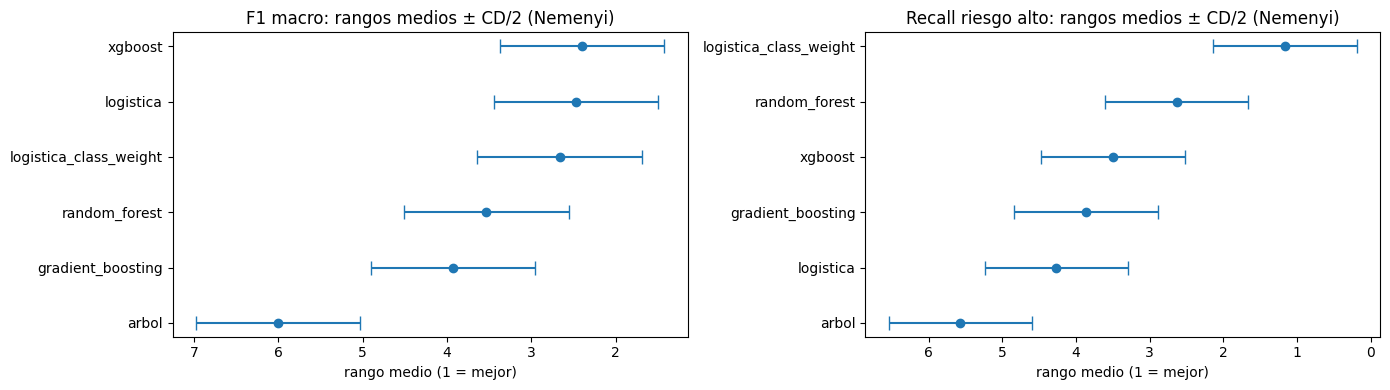

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, rangos, titulo in [(axes[0], rangos_f1, "F1 macro"), (axes[1], rangos_recall, "Recall riesgo alto")]:
    rangos = rangos.sort_values(ascending=False)
    ax.errorbar(rangos, range(len(rangos)), xerr=cd / 2, fmt="o", capsize=5)
    ax.set_yticks(range(len(rangos)), rangos.index)
    ax.set_xlabel("rango medio (1 = mejor)")
    ax.set_title(f"{titulo}: rangos medios ± CD/2 (Nemenyi)")
    ax.invert_xaxis()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparacion_rangos_nemenyi.png", dpi=150)
plt.show()

En la figura cada barra mide la mitad de la diferencia crítica a cada lado: si las barras de dos modelos no se tocan, la diferencia es significativa.

- El test de Friedman sale muy significativo en las dos métricas (p < 0,001 en F1 macro y en recall de riesgo alto), así que no todos los modelos son iguales.
- En F1 macro, con Nemenyi (CD = 1,95) solo el árbol es significativamente peor que el resto. Entre los otros cinco no se puede decir cuál es mejor: XGBoost (2,40), la logística (2,47) y la logística con `class_weight` (2,67) tienen casi el mismo rango medio.
- En recall de riesgo alto la logística con `class_weight` queda primera en casi todas las particiones (rango medio 1,17). Es significativamente mejor que XGBoost, Gradient Boosting, la logística sin pesos y el árbol. Con Random Forest (2,63) la diferencia no llega a la CD.

### Comparación por parejas

Nemenyi es bastante conservador, así que comparamos también el mejor modelo en cada métrica con el resto con el test de Wilcoxon por parejas, corrigiendo con Holm porque hacemos varias comparaciones a la vez.

In [9]:
def wilcoxon_holm(tabla, referencia):
    filas = []
    for m in tabla.columns.drop(referencia):
        estadistico, p = wilcoxon(tabla[referencia], tabla[m])
        filas.append({"referencia": referencia, "modelo": m,
                      "diferencia_media": (tabla[referencia] - tabla[m]).mean(), "p": p})
    res = pd.DataFrame(filas).sort_values("p").reset_index(drop=True)
    # Holm: el p más pequeño se multiplica por el número de comparaciones, el siguiente por uno menos...
    res["p_holm"] = np.minimum(1, np.maximum.accumulate(res.p * (len(res) - res.index)))
    res["significativo"] = res.p_holm < 0.05
    return res


parejas = pd.concat([wilcoxon_holm(tabla_f1, rangos_f1.index[0]).assign(metrica="f1_macro"),
                     wilcoxon_holm(tabla_recall, rangos_recall.index[0]).assign(metrica="recall_alto")],
                    ignore_index=True)
guardar_tabla(parejas, "comparacion_wilcoxon")
parejas.round(4)

,referencia,modelo,diferencia_media,p,p_holm,significativo,metrica
0,xgboost,arbol,0.1173,0.0001,0.0003,True,f1_macro
1,xgboost,gradient_boosting,0.0204,0.0012,0.0046,True,f1_macro
2,xgboost,random_forest,0.0148,0.0353,0.1060,False,f1_macro
3,xgboost,logistica_class_weight,0.0045,0.5245,1.0000,False,f1_macro
4,xgboost,logistica,0.0038,0.5614,1.0000,False,f1_macro
5,logistica_class_weight,gradient_boosting,0.0767,0.0006,0.0032,True,recall_alto
6,logistica_class_weight,logistica,0.0822,0.0007,0.0032,True,recall_alto
7,logistica_class_weight,arbol,0.1460,0.0010,0.0032,True,recall_alto
8,logistica_class_weight,xgboost,0.0739,0.0011,0.0032,True,recall_alto
9,logistica_class_weight,random_forest,0.0509,0.0020,0.0032,True,recall_alto


- En F1 macro, XGBoost es significativamente mejor que Gradient Boosting y que el árbol, pero no que Random Forest (p corregido 0,11) ni que las dos logísticas (p de 0,52 y 0,56, con una diferencia media de 4 milésimas).
- En recall de riesgo alto la logística con `class_weight` es significativamente mejor que todos los demás, también que Random Forest (p corregido 0,003 en todas las comparaciones).
- Hay que tener en cuenta que las 15 particiones de la validación cruzada 5x3 no son independientes, porque comparten pacientes. Por eso estos p-valores salen algo optimistas. Las conclusiones que salen con mucho margen (el árbol es peor y la logística con pesos detecta mejor el riesgo alto) no cambian por esto, pero las que salen justas habría que tomarlas con cuidado.

## 7. Tabla final

Juntamos todo en una tabla y la guardamos para la memoria.

In [10]:
tabla_final = (rendimiento[["cv_f1_macro_mean", "cv_f1_macro_std", "cv_recall_alto_mean", "test_f1_macro",
                           "test_recall_alto", "test_auc_macro", "test_alto_como_bajo"]]
               .join(complejidad[["entrenamiento_s", "parametros_aprendidos"]])
               .join(robustez[["rango_preprocesamiento"]])
               .join(interpretabilidad[["interpretabilidad"]])
               .join(pd.DataFrame({"rango_f1": rangos_f1, "rango_recall_alto": rangos_recall})))
guardar_tabla(tabla_final.reset_index(), "comparacion_final")
tabla_final.round(3)

,cv_f1_macro_mean,cv_f1_macro_std,cv_recall_alto_mean,test_f1_macro,test_recall_alto,test_auc_macro,test_alto_como_bajo,entrenamiento_s,parametros_aprendidos,rango_preprocesamiento,interpretabilidad,rango_f1,rango_recall_alto
modelo,,,,,,,,,,,,,
xgboost,0.645,0.027,0.679,0.715,0.722,0.869,3,0.402,8012,0.022,baja,2.400,3.500
logistica,0.641,0.029,0.670,0.697,0.700,0.861,5,0.077,102,0.019,alta,2.467,4.267
logistica_class_weight,0.640,0.026,0.753,0.674,0.778,0.850,2,0.078,102,0.019,alta,2.667,1.167
gradient_boosting,0.625,0.026,0.676,0.656,0.722,0.847,3,7.022,15354,0.026,baja,3.933,3.867
random_forest,0.630,0.026,0.702,0.644,0.689,0.853,2,0.723,80298,0.042,baja,3.533,2.633
arbol,0.528,0.028,0.607,0.530,0.622,0.749,12,0.165,97,0.023,alta,6.000,5.567


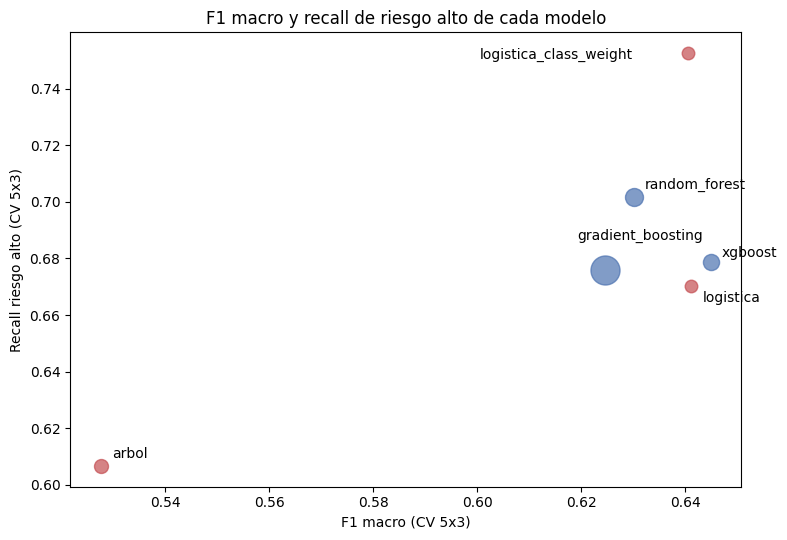

In [11]:
desplazamiento = {"xgboost": (8, 4), "logistica": (8, -12), "gradient_boosting": (-20, 22),
                  "random_forest": (8, 6), "logistica_class_weight": (-150, -4), "arbol": (8, 6)}
fig, ax = plt.subplots(figsize=(8, 5.5))
for nombre, fila in tabla_final.iterrows():
    color = "#C44E52" if fila.interpretabilidad == "alta" else "#4C72B0"
    ax.scatter(fila.cv_f1_macro_mean, fila.cv_recall_alto_mean, s=40 + 150 * np.sqrt(fila.entrenamiento_s),
               color=color, alpha=0.7)
    ax.annotate(nombre, (fila.cv_f1_macro_mean, fila.cv_recall_alto_mean), xytext=desplazamiento[nombre],
                textcoords="offset points")
ax.set_xlabel("F1 macro (CV 5x3)")
ax.set_ylabel("Recall riesgo alto (CV 5x3)")
ax.set_title("F1 macro y recall de riesgo alto de cada modelo")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparacion_modelos.png", dpi=150)
plt.show()

En rojo los modelos interpretables y en azul los que no. El tamaño del punto crece con el tiempo de entrenamiento.

## 8. Conclusiones

Elegimos la **regresión logística con `class_weight`** (imputación KNN, Yeo-Johnson y `C=1`) como mejor modelo para este problema:

- **Rendimiento**: su F1 macro es estadísticamente igual al de XGBoost, que es el mejor. Y tiene el mejor recall de riesgo alto, con diferencia significativa sobre el resto de modelos: en test detecta 70 de los 90 pacientes de riesgo alto y solo clasifica a 2 como riesgo bajo.
- **Complejidad**: 102 parámetros y se entrena en menos de una décima de segundo.
- **Interpretabilidad**: los coeficientes tienen sentido clínico y se pueden explicar a un médico.
- **Robustez**: depende poco del preprocesamiento y no empeora en test.

El precio es que da más falsas alarmas (precisión de riesgo alto de 0,61 frente a 0,70 de XGBoost). En un cribado de riesgo cardiovascular nos parece aceptable, porque una falsa alarma solo supone más seguimiento.

Si solo importara el F1 macro, la alternativa sería **XGBoost**: tiene el mejor F1 macro en test (0,715) y es el que mejor predice la clase moderado. Pero no es significativamente mejor que la logística y es mucho más difícil de explicar.

Otras conclusiones:

- En este dataset los ensembles no mejoran a un modelo lineal. Creemos que el riesgo depende de muchas variables con efectos pequeños que casi se suman, y eso la logística ya lo recoge. La capacidad extra de los ensembles se va en ajustar el ruido del train.
- El balanceo es la parte del preprocesamiento que más influye, mucho más que la imputación o el escalado.
- La clase moderado es la más difícil en todos los modelos. Como mejoras se podría probar a ajustar los umbrales de decisión para la clase alto, un modelo ordinal (las clases tienen orden), calibrar las probabilidades o usar SHAP para explicar los ensembles.